# **Colors**

Цвета часто представляются в компьютерах в виде векторов с тремя измерениями: красным, зеленым и синим (RGB). Другими словами, цвет выражается в виде триплета RGB (r, g, b), каждый компонент которого может варьироваться от нуля до определенного максимального значения:

![rgb slider](https://upload.wikimedia.org/wikipedia/commons/1/12/RGB_sliders.svg)


Если все компоненты равны нулю, то получается черный цвет. Если, напротив, все компоненты максимальны, то получается максимально яркий белый цвет.


В этом разделе вы попрактикуетесь в основных векторных операциях с цветными векторами из [xkcd color survey](https://blog.xkcd.com/2010/05/03/color-survey-results/).

## **Loading the data**

Сначала мы загрузим исходный JSON-файл в словарь Python.

In [5]:
import requests, json

url = 'https://raw.githubusercontent.com/evgeniyako-edu/corpora/master/data/colors/xkcd.json'
response = requests.get(url)

raw_data = json.loads(response.text)

Посмотрим на содержимое `raw_data`.

In [6]:
raw_data

{'description': 'The 954 most common RGB monitor colors, as defined by several hundred thousand participants in the xkcd color name survey.',
 'colors': [{'color': 'cloudy blue', 'hex': '#acc2d9'},
  {'color': 'dark pastel green', 'hex': '#56ae57'},
  {'color': 'dust', 'hex': '#b2996e'},
  {'color': 'electric lime', 'hex': '#a8ff04'},
  {'color': 'fresh green', 'hex': '#69d84f'},
  {'color': 'light eggplant', 'hex': '#894585'},
  {'color': 'nasty green', 'hex': '#70b23f'},
  {'color': 'really light blue', 'hex': '#d4ffff'},
  {'color': 'tea', 'hex': '#65ab7c'},
  {'color': 'warm purple', 'hex': '#952e8f'},
  {'color': 'yellowish tan', 'hex': '#fcfc81'},
  {'color': 'cement', 'hex': '#a5a391'},
  {'color': 'dark grass green', 'hex': '#388004'},
  {'color': 'dusty teal', 'hex': '#4c9085'},
  {'color': 'grey teal', 'hex': '#5e9b8a'},
  {'color': 'macaroni and cheese', 'hex': '#efb435'},
  {'color': 'pinkish tan', 'hex': '#d99b82'},
  {'color': 'spruce', 'hex': '#0a5f38'},
  {'color': 'str

Вы можете заметить, что исходный формат не очень удобен в использовании. Давайте преобразуем шестнадцатеричные значения цвета в RGB-триплеты и создадим новый словарь { "color_name": [r, g, b]}.

Для этого запустим ячейки, указанные ниже.

In [7]:
def hex_to_rgb(color_hex):
    color_hex = color_hex.lstrip("#")
    return [int(color_hex[:2], 16), int(color_hex[2:4], 16), int(color_hex[4:6], 16)]

In [8]:
colors = dict()

for item in raw_data['colors']:
    colors[item['color']] = hex_to_rgb(item['hex'])

Теперь взгляните на содержание словаря **colors**.

In [9]:
colors

{'cloudy blue': [172, 194, 217],
 'dark pastel green': [86, 174, 87],
 'dust': [178, 153, 110],
 'electric lime': [168, 255, 4],
 'fresh green': [105, 216, 79],
 'light eggplant': [137, 69, 133],
 'nasty green': [112, 178, 63],
 'really light blue': [212, 255, 255],
 'tea': [101, 171, 124],
 'warm purple': [149, 46, 143],
 'yellowish tan': [252, 252, 129],
 'cement': [165, 163, 145],
 'dark grass green': [56, 128, 4],
 'dusty teal': [76, 144, 133],
 'grey teal': [94, 155, 138],
 'macaroni and cheese': [239, 180, 53],
 'pinkish tan': [217, 155, 130],
 'spruce': [10, 95, 56],
 'strong blue': [12, 6, 247],
 'toxic green': [97, 222, 42],
 'windows blue': [55, 120, 191],
 'blue blue': [34, 66, 199],
 'blue with a hint of purple': [83, 60, 198],
 'booger': [155, 181, 60],
 'bright sea green': [5, 255, 166],
 'dark green blue': [31, 99, 87],
 'deep turquoise': [1, 115, 116],
 'green teal': [12, 181, 119],
 'strong pink': [255, 7, 137],
 'bland': [175, 168, 139],
 'deep aqua': [8, 120, 127],
 

## **Построение графиков данных**

Чтобы иметь лучшее представление о том, какие цвета присутствуют в нашем наборе данных, давайте построим их в виде точек в трехмерном пространстве (с красным, зеленым и синим в качестве осей).

Присвойте каждой точке цвет, который она представляет.

Подсказка 1: [$\texttt{scatter3D}$](https://matplotlib.org/stable/gallery/mplot3d/scatter3d.html) функция из библиотеки $\texttt{matplotlib}$ позволяет строить график расположения точек в пространстве.

Подсказка 2: В $\texttt{matplotlib}$, вы можете указать цвет, указав его название из опроса xkcd с помощью
$\texttt{'xkcd:'}$ префикса. Туториал по ссылке [documentation](https://matplotlib.org/3.1.0/tutorials/colors/colors.html).

In [10]:
import matplotlib.pyplot as plt
import matplotlib._color_data as mcd


Text(0.5, 0, 'Z Label')

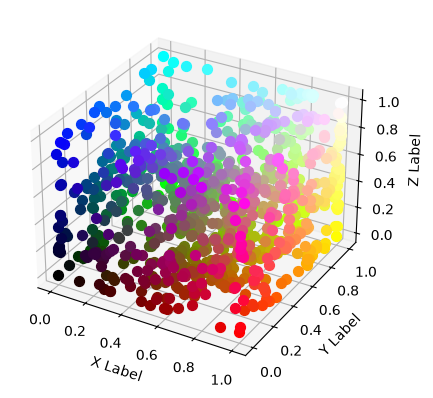

In [30]:
colors = {key: value for key, value in colors.items()
           if "xkcd:" + key in mcd.XKCD_COLORS}

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

for key, value in colors.items():
    r = value[0] / 255.0
    g = value[1] / 255.0 
    b = value[2] / 255.0
    # ax.scatter(xs, ys, zs, c=(xs, ys, zs))
    ax.scatter3D(r,g,b, color = 'xkcd:' + key, s= 50)

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

Взгляните на график, который вы получили. Где расположены "красноватые", "зеленоватые" и "голубоватые" цвета? Что вы можете сказать о расположении похожих цветов?

## **Расстояние между цветами**

Вспомните, что Евклидово расстояние между двумя точками $x=(x_1, ..., x_n)$ and $y = (y_1, ..., y_n)$ в  $n$-размерном пространстве определяется как:

$dist(x, y) = ||x-y||_2 = \sqrt{(x_1-y_1)^2 + ... + (x_n-y_n)^2}$.

Реализуйте функцию, которая вычисляет евклидово расстояние между двумя цветами в RGB-пространстве.

In [18]:
import numpy as np

def distance(color1: list[int], color2: list[int]):
  return np.sqrt(np.sum([(x-y)**2 for x,y in zip(color1, color2)]))
  

Попробуйте использовать свою функцию для вычисления расстояний между разными цветами в данных. Что вы наблюдаете?

In [19]:
distance(colors['red'], colors['dark red'])

np.float64(97.0)

In [20]:
distance(colors['red'], colors['blue'])

np.float64(324.49036965678965)

Теперь реализуем функцию, которая, учитывая некоторый RGB-вектор, возвращает n ближайших цветов из нашего словаря **colors**.

In [26]:

def find_n_closest(colors, new_color, n=5):
  closest = []
  for key in sorted(colors.keys(),key = lambda x: distance(new_color, colors[x]))[:n]:
    closest.append(key)
  return closest

Теперь давайте возьмем какой-нибудь случайный новый цвет и найдем в нашем словаре $n=10$ наиболее близких к нему цветов.

Поэкспериментируйте с разными цветами!

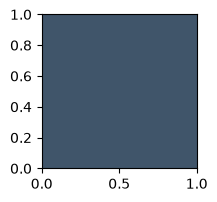

In [27]:

new_color = [30, 40, 50]
fig, ax = plt.subplots(1, 1, figsize=(2, 2))
ax.set_facecolor(np.array(new_color)/sum(new_color))



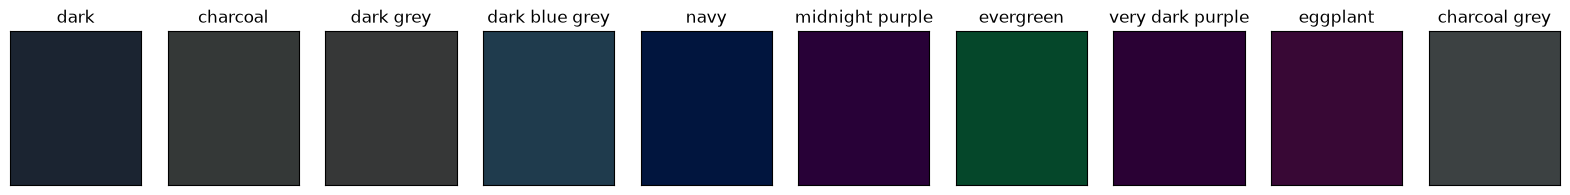

In [28]:
n = 10

closest = find_n_closest(colors, new_color, n)

fig, axs  = plt.subplots(1, n, figsize = (n*2,2))
for ax, c in zip(axs, closest):
  ax.set_facecolor('xkcd:' + c)
  ax.set_xticks([])
  ax.set_yticks([])
  ax.set_title(c)

## **Операции с векторами**

Давайте теперь попробуем выполнить некоторые векторные операции с RGB-векторами.

**Сложение векторов**

Определим функцию, которая суммирует векторы.

In [38]:
def add_colors(color1, color2):

    color1 = colors[color1]
    color2 = colors[color2]

    return [x + y for x, y in zip(color1, color2)]

Рассмотрим, например, два цвета $\texttt{red}$ и $\texttt{blue}$:

Text(0.5, 1.0, 'blue')

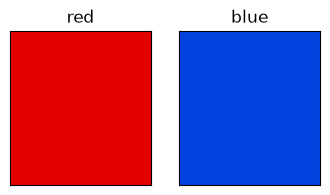

In [33]:
color1 = 'red'
color2 = 'blue'

# Plotting the colors
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(4, 2))
ax1.set_facecolor('xkcd:'+color1)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_title(color1)

ax2.set_facecolor('xkcd:'+color2)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_title(color2)

Какие цвета в нашем словаре наиболее близки к сумме этих двух цветов?

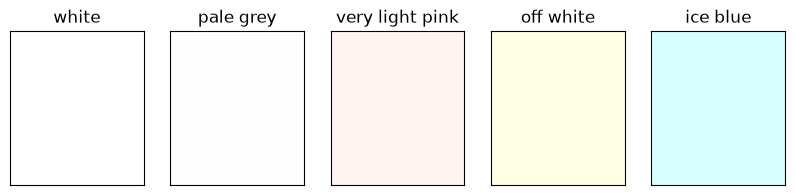

In [48]:
n = 5

color1 = 'black'
color2 = 'white'

closest = find_n_closest(colors, add_colors(color1, color2), n)

fig, axs  = plt.subplots(1, n, figsize = (n*2,2))
for ax, c in zip (axs, closest):
  ax.set_facecolor('xkcd:' + c)
  ax.set_xticks([])
  ax.set_yticks([])
  ax.set_title(c)


Поэкспериментируйте с другими цветами

### Вычитание векторов

Определите функцию, которая вычитает один вектор из другого

In [54]:
def subtract_colors(color1, color2):
    
    color1 = colors[color1]
    color2 = colors[color2]

    return [max(x - y, 0) for x, y in zip(color1, color2)]

Теперь давайте рассмотрим $\texttt{purple}$ и $\texttt{red}$:

Text(0.5, 1.0, 'red')

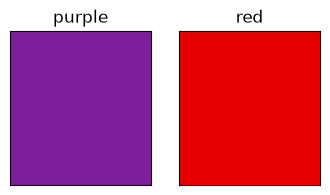

In [55]:
color1 = 'purple'
color2 = 'red'

# Plotting the colors
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(4, 2))
ax1.set_facecolor('xkcd:'+color1)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_title(color1)

ax2.set_facecolor('xkcd:'+color2)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_title(color2)

Какова их разница? Найдите наиболее близкие цвета в нашем словаре.

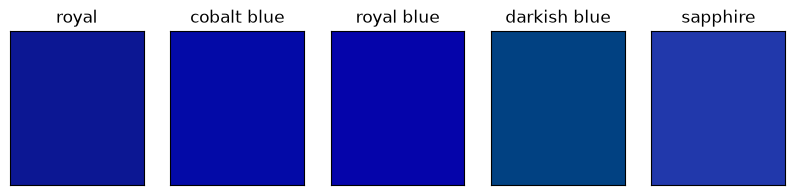

In [56]:
n = 5

new_color = subtract_colors(color1, color2)

closest = find_n_closest(colors, new_color, n)

fig, axs  = plt.subplots(1, n, figsize = (n*2,2))
for ax, c in zip (axs, closest):
  ax.set_facecolor('xkcd:' + c)
  ax.set_xticks([])
  ax.set_yticks([])
  ax.set_title(c)


## **Источники**

This notebook is inspired by a [tutorial by Allison Parrish](https://gist.github.com/aparrish/2f562e3737544cf29aaf1af30362f469).